# Brain Tumor Classification — Dataset and Model Diagnostic Audit

This notebook audits the seven potential causes of limited generalisation in the four-class brain MRI project:

1. Data leakage and duplicate images
2. Potential label errors / noisy labels
3. Background and acquisition bias
4. Feature-space separability
5. Class imbalance
6. Image resolution and preprocessing
7. Fine-tuning strategy

**Classes:** `glioma`, `meningioma`, `notumor`, `pituitary`

The notebook is diagnostic: it flags suspicious cases for review. It does **not** automatically declare an image incorrectly labelled, and it does not establish clinical validity.

Run the cells from top to bottom. Start by checking the configuration paths below.

## 0. Configuration

In [1]:
from pathlib import Path
import os, random, hashlib, json, time, warnings, math
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# EDIT THESE PATHS to match your project.
# Expected structure:
# dataset/
#   train/{glioma,meningioma,notumor,pituitary}/
#   test/{glioma,meningioma,notumor,pituitary}/
PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "data"
TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"

# Optional: point to your saved fine-tuned model.
# Leave as None if you want to run dataset-only diagnostics first.
MODEL_PATH = PROJECT_DIR / "models" / "resnet50_finetune.keras"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

OUTPUT_DIR = PROJECT_DIR / "diagnostic_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR.resolve())
print("Train exists:", TRAIN_DIR.exists(), TRAIN_DIR)
print("Test exists:", TEST_DIR.exists(), TEST_DIR)
print("Model exists:", Path(MODEL_PATH).exists() if MODEL_PATH else False, MODEL_PATH)

Project: E:\SEM5\ERA\ERA_Project\Brain_Tumor
Train exists: True e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Training
Test exists: True e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testing
Model exists: True e:\SEM5\ERA\ERA_Project\Brain_Tumor\models\resnet50_finetune.keras


## 1. Environment and dataset inventory

In [2]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

def collect_image_records(split_dir, split_name):
    records = []
    if not split_dir.exists():
        return records
    for class_dir in sorted([p for p in split_dir.iterdir() if p.is_dir()]):
        for p in class_dir.rglob("*"):
            if p.is_file() and p.suffix.lower() in VALID_EXTS:
                records.append({
                    "split": split_name,
                    "label": class_dir.name,
                    "path": str(p),
                    "filename": p.name,
                    "stem": p.stem
                })
    return records

records = collect_image_records(TRAIN_DIR, "train") + collect_image_records(TEST_DIR, "test")
manifest = pd.DataFrame(records)
if manifest.empty:
    raise FileNotFoundError("No images found. Correct DATASET_DIR / TRAIN_DIR / TEST_DIR in Section 0.")

print("Total images:", len(manifest))
display(manifest.groupby(["split", "label"]).size().unstack(fill_value=0))
print("\\nUnexpected class folders:", sorted(set(manifest.label) - set(CLASS_NAMES)))
print("Missing expected folders:",
      sorted(set(CLASS_NAMES) - set(manifest.loc[manifest.split=='train', 'label'])))

manifest.to_csv(OUTPUT_DIR / "image_manifest.csv", index=False)

TensorFlow: 2.21.0
NumPy: 2.2.6
Pandas: 2.3.3
GPU devices: []
Total images: 7200


label,glioma,meningioma,notumor,pituitary
split,,,,
test,400,400,400,400
train,1400,1400,1400,1400


\nUnexpected class folders: []
Missing expected folders: []


## 2. Data leakage and duplicate-image audit

This section checks:
- Exact duplicates using SHA-256 file hashes
- Same filename/stem across train and test
- Near-duplicates using perceptual hashes (optional dependency `ImageHash`)

An exact or near-duplicate across train and test can inflate test performance. Same filename alone is a warning, not proof of duplication.

In [3]:
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

hashes = []
for p in manifest.path:
    try:
        hashes.append(sha256_file(p))
    except Exception as e:
        hashes.append(None)
manifest["sha256"] = hashes

duplicate_hashes = manifest.dropna(subset=["sha256"]).groupby("sha256").filter(lambda x: len(x) > 1)
cross_split_exact = duplicate_hashes.groupby("sha256").filter(lambda x: x.split.nunique() > 1)
print("Files participating in any exact duplicate group:", len(duplicate_hashes))
print("Files participating in cross-split exact duplicates:", len(cross_split_exact))
if not cross_split_exact.empty:
    display(cross_split_exact[["split","label","filename","path","sha256"]].sort_values("sha256"))
else:
    print("No exact cross-split duplicates detected.")

stem_groups = manifest.groupby("stem").filter(lambda x: x.split.nunique() > 1)
print("\\nSame filename stem across train/test:", len(stem_groups))
if not stem_groups.empty:
    display(stem_groups[["split","label","filename","path"]].sort_values("stem"))

try:
    import imagehash
    phashes = []
    for p in manifest.path:
        try:
            with Image.open(p) as im:
                phashes.append(str(imagehash.phash(im.convert("RGB"))))
        except Exception:
            phashes.append(None)
    manifest["phash"] = phashes
    # Pairwise comparisons across splits; threshold <= 4 is a conservative near-duplicate flag.
    train_rows = manifest[manifest.split == "train"].dropna(subset=["phash"])
    test_rows = manifest[manifest.split == "test"].dropna(subset=["phash"])
    near = []
    for _, tr in train_rows.iterrows():
        h1 = imagehash.hex_to_hash(tr.phash)
        for _, te in test_rows.iterrows():
            d = h1 - imagehash.hex_to_hash(te.phash)
            if d <= 4:
                near.append((tr.path, tr.label, te.path, te.label, d))
    near_df = pd.DataFrame(near, columns=["train_path","train_label","test_path","test_label","phash_distance"])
    print("Near-duplicate train/test pairs (pHash distance <= 4):", len(near_df))
    if len(near_df): display(near_df.sort_values("phash_distance"))
except ImportError:
    print("Optional near-duplicate check skipped. Install with: %pip install ImageHash")

manifest.to_csv(OUTPUT_DIR / "image_manifest_with_hashes.csv", index=False)

Files participating in any exact duplicate group: 340
Files participating in cross-split exact duplicates: 0
No exact cross-split duplicates detected.
\nSame filename stem across train/test: 0
Optional near-duplicate check skipped. Install with: %pip install ImageHash


### Patient-level leakage check

Image-level deduplication cannot detect different slices from the same patient. If filenames encode patient/study identifiers, inspect them below. You must define the correct ID extraction rule for this dataset; do not assume the filename stem is a patient ID.

In [4]:
# Inspect filename patterns before defining an ID parser.
display(manifest[["filename","stem","split","label"]].head(30))

# EDIT this function only if you know the dataset's patient/study ID convention.
# Default returns None, so no unsupported patient-level conclusion is made.
def extract_patient_id(filename):
    return None

manifest["patient_id"] = manifest.filename.map(extract_patient_id)
if manifest.patient_id.notna().any():
    patient_split = manifest.dropna(subset=["patient_id"]).groupby("patient_id").split.nunique()
    leaking_patients = patient_split[patient_split > 1]
    print("Patient IDs found:", manifest.patient_id.nunique())
    print("Patient IDs appearing in multiple splits:", len(leaking_patients))
    display(manifest[manifest.patient_id.isin(leaking_patients.index)].sort_values("patient_id"))
else:
    print("Patient-level leakage is NOT assessable until extract_patient_id() is configured from dataset documentation.")

,filename,stem,split,label
0,Tr-gl_1.jpg,Tr-gl_1,train,glioma
1,Tr-gl_10.jpg,Tr-gl_10,train,glioma
2,Tr-gl_100.jpg,Tr-gl_100,train,glioma
3,Tr-gl_1000.jpg,Tr-gl_1000,train,glioma
4,Tr-gl_1001.jpg,Tr-gl_1001,train,glioma
5,Tr-gl_1002.jpg,Tr-gl_1002,train,glioma
6,Tr-gl_1003.jpg,Tr-gl_1003,train,glioma
7,Tr-gl_1004.jpg,Tr-gl_1004,train,glioma
8,Tr-gl_1005.jpg,Tr-gl_1005,train,glioma
9,Tr-gl_1006.jpg,Tr-gl_1006,train,glioma


Patient-level leakage is NOT assessable until extract_patient_id() is configured from dataset documentation.


## 3. Label consistency and potential label-noise review

Without an authoritative annotation file or expert review, image pixels alone cannot prove the correct diagnosis. This section identifies:
- Identical image files assigned different labels
- Suspicious filename/stem collisions
- Images the trained model predicts with high confidence against their folder label (a review queue, **not** proof of a wrong label)

First inspect duplicate groups with conflicting labels.

In [5]:
conflicting_exact = (
    manifest.dropna(subset=["sha256"])
    .groupby("sha256")
    .filter(lambda x: x.label.nunique() > 1)
)
print("Exact duplicate groups/files with conflicting labels:")
if conflicting_exact.empty:
    print("None found.")
else:
    display(conflicting_exact[["split","label","filename","path","sha256"]].sort_values("sha256"))

conflicting_stems = manifest.groupby("stem").filter(lambda x: x.label.nunique() > 1)
print("\\nSame stem assigned different labels:")
if conflicting_stems.empty:
    print("None found.")
else:
    display(conflicting_stems[["split","label","filename","path"]].sort_values("stem"))

Exact duplicate groups/files with conflicting labels:
None found.
\nSame stem assigned different labels:
None found.


### Optional model-assisted label review

In [6]:
# This cell runs only if a compatible saved model exists.
# A confident disagreement is a manual-review candidate, not an automatic relabel.
import tensorflow as tf

model = None
if MODEL_PATH and Path(MODEL_PATH).exists():
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    print("Loaded:", MODEL_PATH)
    print("Model input:", model.input_shape, "output:", model.output_shape)
else:
    print("Model not loaded. Set MODEL_PATH to your saved .keras model to run this section.")

# IMPORTANT: Select preprocessing that matches the model used during training.
# For ResNet50 ImageNet preprocessing use "resnet50".
# For VGG16 ImageNet preprocessing use "vgg16".
# If your model included a Rescaling layer or a custom preprocessing layer,
# adapt this function to match the original training pipeline exactly.
MODEL_ARCH = "resnet50"  # "resnet50" or "vgg16"

def preprocess_for_model(batch):
    batch = tf.cast(batch, tf.float32)
    if MODEL_ARCH.lower() == "resnet50":
        return tf.keras.applications.resnet50.preprocess_input(batch)
    elif MODEL_ARCH.lower() == "vgg16":
        return tf.keras.applications.vgg16.preprocess_input(batch)
    raise ValueError("Set MODEL_ARCH to resnet50 or vgg16.")

def load_one_image(path, size=IMG_SIZE):
    im = Image.open(path).convert("RGB").resize((size[1], size[0]))
    return np.asarray(im, dtype=np.float32)

label_to_idx = {name:i for i,name in enumerate(CLASS_NAMES)}
review_rows = []
if model is not None:
    for start in range(0, len(manifest), BATCH_SIZE):
        batch_df = manifest.iloc[start:start+BATCH_SIZE]
        imgs, valid_rows = [], []
        for idx, row in batch_df.iterrows():
            if row.label not in label_to_idx:
                continue
            try:
                imgs.append(load_one_image(row.path))
                valid_rows.append((idx, row))
            except Exception as e:
                print("Unreadable:", row.path, e)
        if not imgs:
            continue
        x = preprocess_for_model(np.stack(imgs))
        probs = model.predict(x, verbose=0)
        for (idx,row), prob in zip(valid_rows, probs):
            true_idx = label_to_idx[row.label]
            pred_idx = int(np.argmax(prob))
            review_rows.append({
                "path": row.path, "split": row.split, "true_label": row.label,
                "predicted_label": CLASS_NAMES[pred_idx],
                "confidence": float(prob[pred_idx]),
                "true_class_probability": float(prob[true_idx]),
                "disagreement": pred_idx != true_idx
            })
    review_df = pd.DataFrame(review_rows)
    display(review_df[(review_df.disagreement) & (review_df.confidence >= 0.80)]
            .sort_values("confidence", ascending=False).head(100))
    review_df.to_csv(OUTPUT_DIR / "model_label_review_candidates.csv", index=False)
else:
    print("Skipped: no model loaded.")

Loaded: e:\SEM5\ERA\ERA_Project\Brain_Tumor\models\resnet50_finetune.keras
Model input: (None, 224, 224, 3) output: (None, 4)


,path,split,true_label,predicted_label,confidence,true_class_probability,disagreement
2686,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,train,meningioma,notumor,0.999961,0.000001,True
6302,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,test,meningioma,notumor,0.999961,0.000001,True
5732,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,test,glioma,notumor,0.999805,0.000112,True
5969,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,test,glioma,meningioma,0.999785,0.000211,True
5638,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,test,glioma,notumor,0.999603,0.000072,True
...,...,...,...,...,...,...,...
5619,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testi...,test,glioma,pituitary,0.982940,0.000609,True
1400,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,train,meningioma,pituitary,0.982017,0.014797,True
1052,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,train,glioma,meningioma,0.981950,0.003839,True
1679,e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Train...,train,meningioma,pituitary,0.981696,0.014944,True


## 4. Background and acquisition-bias audit

This section measures simple image-level signals:
- Mean and standard deviation of RGB channels
- Brightness and contrast
- Image dimensions and aspect ratio
- Border brightness (a rough indicator of borders/padding)

It then compares these signals by class and split. Large differences can indicate acquisition or preprocessing differences. These statistics cannot prove that the model uses background shortcuts; Grad-CAM and controlled masking experiments are needed for that.

width  height  aspect_ratio  brightness_mean  \
split label                                                      
test  glioma      512.0   512.0           1.0        35.770000   
      meningioma  512.0   512.0           1.0        42.869999   
      notumor     227.0   234.0           1.0        56.250000   
      pituitary   512.0   512.0           1.0        49.450001   
train glioma      512.0   512.0           1.0        31.940001   
      meningioma  512.0   512.0           1.0        40.990002   
      notumor     230.0   244.0           1.0        57.770000   
      pituitary   512.0   512.0           1.0        49.660000   

                  brightness_std  border_brightness  
split label                                          
test  glioma           40.369999               4.45  
      meningioma       46.790001               7.07  
      notumor          58.680000               9.54  
      pituitary        41.880001              13.72  
train glioma           38.549999               3.05  
      meningioma       45.410000               6.87  
      notumor          58.580002              10.89  
      pituitary        41.400002              13.47

<Figure size 1100x400 with 0 Axes>

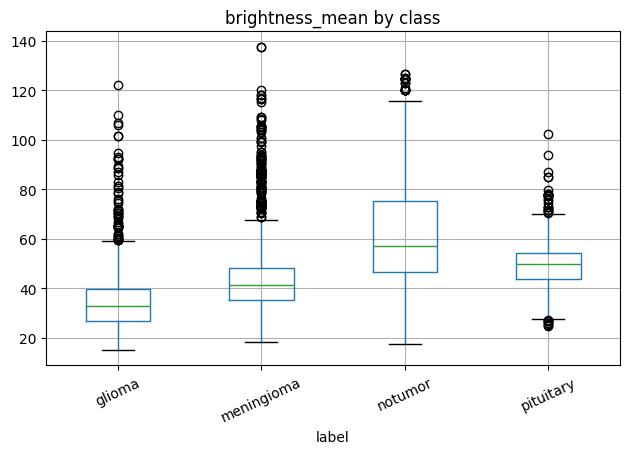

<Figure size 1100x400 with 0 Axes>

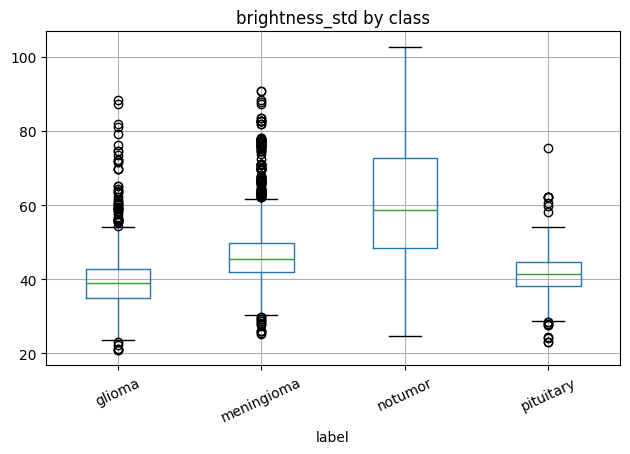

<Figure size 1100x400 with 0 Axes>

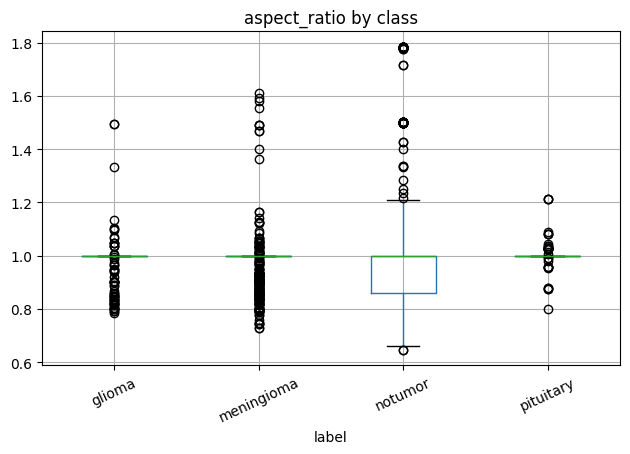

<Figure size 1100x400 with 0 Axes>

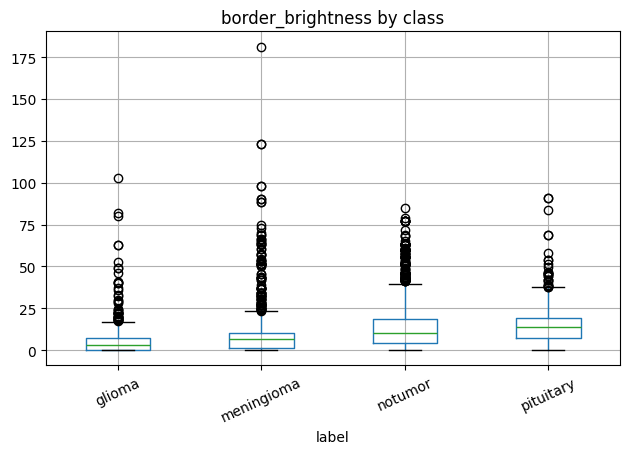

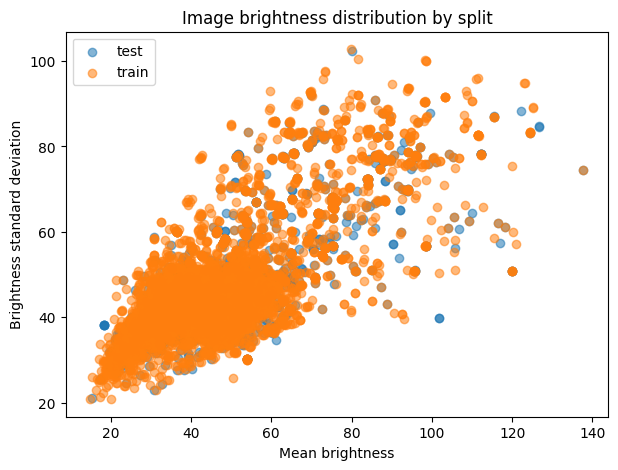

In [7]:
def image_statistics(path):
    with Image.open(path) as im:
        original_size = im.size
        arr = np.asarray(im.convert("RGB"), dtype=np.float32)
    gray = 0.299*arr[:,:,0] + 0.587*arr[:,:,1] + 0.114*arr[:,:,2]
    h,w = gray.shape
    b = max(1, int(min(h,w)*0.05))
    border = np.concatenate([gray[:b,:].ravel(), gray[-b:,:].ravel(),
                             gray[:,:b].ravel(), gray[:,-b:].ravel()])
    return {
        "width": original_size[0], "height": original_size[1],
        "aspect_ratio": original_size[0]/max(1,original_size[1]),
        "r_mean": arr[:,:,0].mean(), "g_mean": arr[:,:,1].mean(),
        "b_mean": arr[:,:,2].mean(), "brightness_mean": gray.mean(),
        "brightness_std": gray.std(), "border_brightness": border.mean()
    }

stats = []
for _, row in manifest.iterrows():
    try:
        stats.append({"path":row.path, "split":row.split, "label":row.label,
                      **image_statistics(row.path)})
    except Exception as e:
        stats.append({"path":row.path, "split":row.split, "label":row.label, "read_error":str(e)})
stats_df = pd.DataFrame(stats)
stats_df.to_csv(OUTPUT_DIR / "image_statistics.csv", index=False)
display(stats_df.groupby(["split","label"])[
    ["width","height","aspect_ratio","brightness_mean","brightness_std","border_brightness"]
].median().round(2))

for feature in ["brightness_mean","brightness_std","aspect_ratio","border_brightness"]:
    plt.figure(figsize=(11,4))
    stats_df.boxplot(column=feature, by="label", rot=25)
    plt.title(f"{feature} by class"); plt.suptitle("")
    plt.tight_layout(); plt.show()

plt.figure(figsize=(7,5))
for split, grp in stats_df.groupby("split"):
    plt.scatter(grp["brightness_mean"], grp["brightness_std"], alpha=.55, label=split)
plt.xlabel("Mean brightness"); plt.ylabel("Brightness standard deviation")
plt.title("Image brightness distribution by split"); plt.legend(); plt.show()

### Can simple image statistics predict the class?

If a very simple model predicts class labels well using only brightness, dimensions and border statistics, that is a warning that acquisition/background cues may correlate with labels. It is not proof of leakage.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

feature_cols = ["width","height","aspect_ratio","r_mean","g_mean","b_mean",
                "brightness_mean","brightness_std","border_brightness"]
bias_df = stats_df.dropna(subset=["label"])
X_bias = bias_df[feature_cols]
y_bias = bias_df["label"]
if y_bias.nunique() > 1 and y_bias.value_counts().min() >= 2:
    bias_model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced")
    )
    cv = StratifiedKFold(n_splits=min(5, int(y_bias.value_counts().min())),
                         shuffle=True, random_state=SEED)
    scores = cross_val_score(bias_model, X_bias, y_bias, cv=cv, scoring="accuracy")
    print("Metadata-only CV accuracy:", scores.mean().round(4), "+/-", scores.std().round(4))
    print("Interpretation: unusually high performance is a shortcut-learning warning, not proof.")
else:
    print("Not enough samples per class for this cross-validation check.")

Metadata-only CV accuracy: 0.6768 +/- 0.0141
Interpretation: unusually high performance is a shortcut-learning warning, not proof.


## 5. Feature-space separability

This section extracts embeddings from the saved model's penultimate layer, then:
- Computes a silhouette score (higher generally means better cluster separation; range -1 to 1)
- Visualises embeddings with PCA and t-SNE
- Reports class-wise centroid distances

Use the exact preprocessing used during training. The model must expose a meaningful penultimate feature layer. If the model architecture differs, inspect `model.summary()` and adjust the feature-layer selection.

In [9]:
if model is not None:
    model.summary()
    print("Top-level layers:")
    for i, layer in enumerate(model.layers[-12:]):
        print(len(model.layers)-12+i, layer.name, layer.output.shape)

    # Default: output of the layer immediately before the final classifier.
    # Adjust FEATURE_LAYER_NAME if your model uses a different head.
    FEATURE_LAYER_NAME = None
    if FEATURE_LAYER_NAME:
        feature_layer = model.get_layer(FEATURE_LAYER_NAME)
    else:
        feature_layer = model.layers[-2]
    feature_model = tf.keras.Model(inputs=model.input, outputs=feature_layer.output)
    print("Using feature layer:", feature_layer.name)
else:
    print("Load a model in Section 3 before extracting embeddings.")

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,121,476 (92.02 MB)

 Trainable params: 14,958,340 (57.06 MB)

 Non-trainable params: 9,163,136 (34.95 MB)

Top-level layers:
-4 input_layer_5 (None, 224, 224, 3)
-3 data_augmentation (None, 224, 224, 3)
-2 resnet50 (None, 7, 7, 2048)
-1 global_average_pooling2d_2 (None, 2048)
0 batch_normalization_1 (None, 2048)
1 dense_4 (None, 256)
2 dropout_2 (None, 256)
3 dense_5 (None, 4)
Using feature layer: dropout_2


Embedding matrix: (7200, 256)
Overall silhouette score (cosine): 0.1581


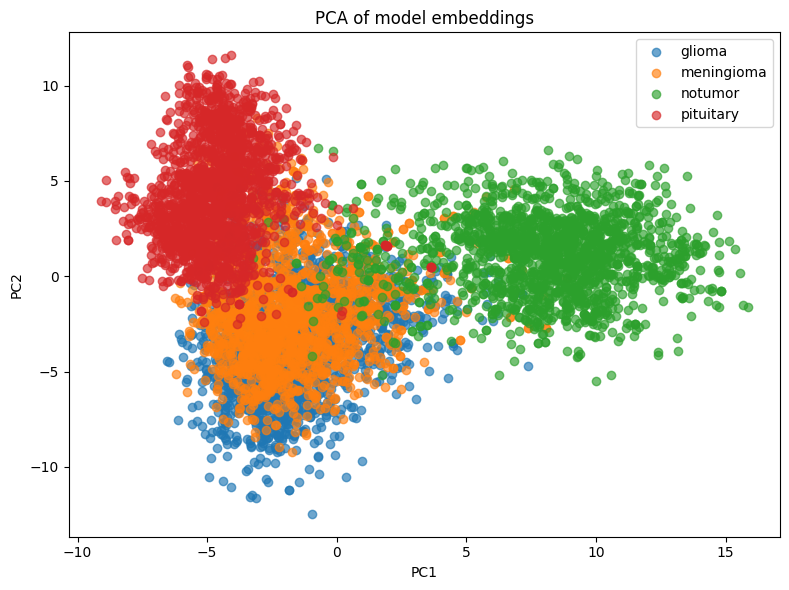

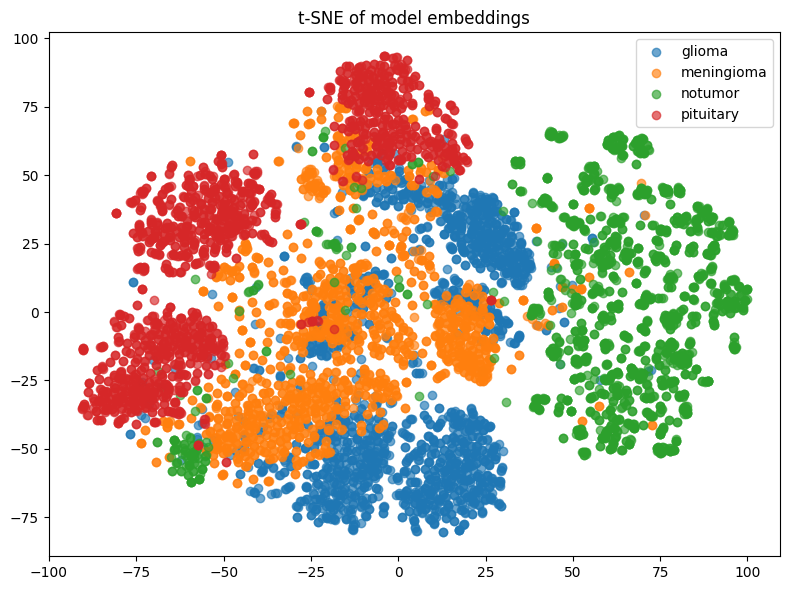

,class_1,class_2,centroid_distance
0,glioma,meningioma,6.486524
4,meningioma,pituitary,8.936275
2,glioma,pituitary,10.242836
3,meningioma,notumor,11.962672
1,glioma,notumor,12.382010
5,notumor,pituitary,14.991469


In [10]:
embedding_rows, embedding_labels, embedding_splits, embedding_paths = [], [], [], []
if model is not None:
    for start in range(0, len(manifest), BATCH_SIZE):
        batch_df = manifest.iloc[start:start+BATCH_SIZE]
        imgs, meta = [], []
        for _, row in batch_df.iterrows():
            if row.label not in label_to_idx: continue
            try:
                imgs.append(load_one_image(row.path))
                meta.append(row)
            except Exception:
                pass
        if not imgs: continue
        x = preprocess_for_model(np.stack(imgs))
        feats = feature_model.predict(x, verbose=0)
        feats = feats.reshape((feats.shape[0], -1))
        for f, row in zip(feats, meta):
            embedding_rows.append(f)
            embedding_labels.append(row.label)
            embedding_splits.append(row.split)
            embedding_paths.append(row.path)

if embedding_rows:
    embeddings = np.asarray(embedding_rows)
    y_embed = np.asarray(embedding_labels)
    print("Embedding matrix:", embeddings.shape)
    if len(np.unique(y_embed)) > 1 and min(Counter(y_embed).values()) >= 2:
        sil = silhouette_score(embeddings, y_embed, metric="cosine")
        print("Overall silhouette score (cosine):", round(float(sil),4))
    else:
        print("Silhouette score unavailable: insufficient class samples.")

    pca = PCA(n_components=2, random_state=SEED)
    emb_pca = pca.fit_transform(StandardScaler().fit_transform(embeddings))
    plt.figure(figsize=(8,6))
    for cls in CLASS_NAMES:
        m = y_embed == cls
        if m.any(): plt.scatter(emb_pca[m,0], emb_pca[m,1], label=cls, alpha=.65)
    plt.title("PCA of model embeddings"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend()
    plt.tight_layout(); plt.show()

    if len(embeddings) >= 10:
        perplexity = min(30, max(2, (len(embeddings)-1)//3))
        emb_tsne = TSNE(n_components=2, random_state=SEED, perplexity=perplexity,
                        init="pca", learning_rate="auto").fit_transform(
                            StandardScaler().fit_transform(embeddings))
        plt.figure(figsize=(8,6))
        for cls in CLASS_NAMES:
            m = y_embed == cls
            if m.any(): plt.scatter(emb_tsne[m,0], emb_tsne[m,1], label=cls, alpha=.65)
        plt.title("t-SNE of model embeddings"); plt.legend(); plt.tight_layout(); plt.show()

    # Euclidean distances between class centroids and within-class scatter.
    centroids = {c: embeddings[y_embed==c].mean(axis=0) for c in np.unique(y_embed)}
    centroid_rows = []
    for c1 in centroids:
        for c2 in centroids:
            if c1 < c2:
                centroid_rows.append({"class_1":c1,"class_2":c2,
                                      "centroid_distance":float(np.linalg.norm(centroids[c1]-centroids[c2]))})
    display(pd.DataFrame(centroid_rows).sort_values("centroid_distance"))
    np.save(OUTPUT_DIR / "embeddings.npy", embeddings)
    pd.DataFrame({"path":embedding_paths,"label":embedding_labels,"split":embedding_splits}).to_csv(
        OUTPUT_DIR / "embedding_index.csv", index=False)
else:
    print("No embeddings generated. Ensure a model is loaded.")

## 6. Class imbalance audit

Class imbalance is measured separately for train and test. The notebook also calculates balanced class weights for the training split. Class weights can compensate in the loss function, but they cannot replace missing examples or correct labels.

label,glioma,meningioma,notumor,pituitary
split,,,,
test,400,400,400,400
train,1400,1400,1400,1400


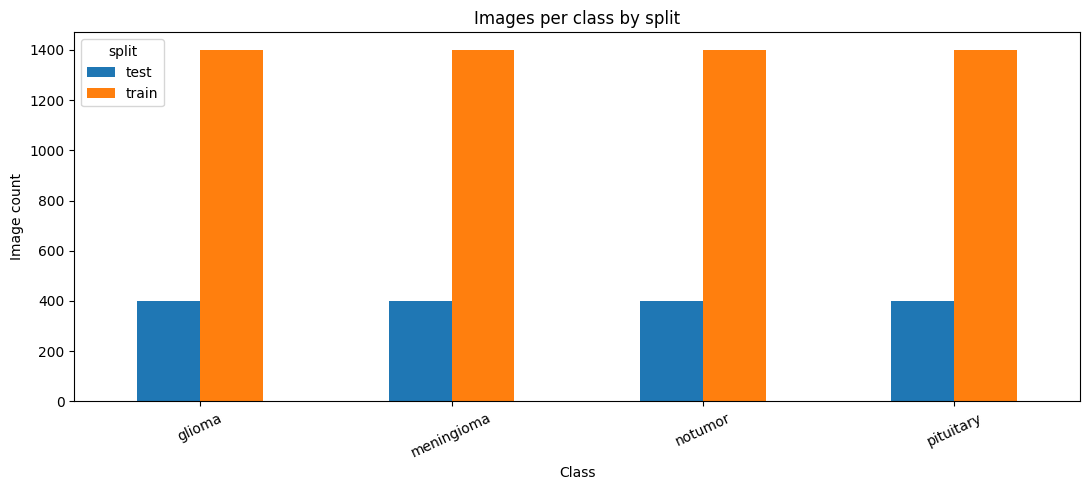

Train majority/minority ratio: 1.0
Train class percentages:


,percentage
label,
glioma,25.0
meningioma,25.0
notumor,25.0
pituitary,25.0


Balanced class weights (class_index: weight): {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0)}


In [11]:
counts = manifest.groupby(["split","label"]).size().unstack(fill_value=0).reindex(
    columns=CLASS_NAMES, fill_value=0)
display(counts)
ax = counts.T.plot(kind="bar", figsize=(11,5))
ax.set_title("Images per class by split"); ax.set_ylabel("Image count")
ax.set_xlabel("Class"); plt.xticks(rotation=25); plt.tight_layout(); plt.show()

train_counts = manifest[manifest.split=="train"].label.value_counts().reindex(CLASS_NAMES, fill_value=0)
imbalance_ratio = (train_counts.max()/train_counts[train_counts>0].min()
                   if (train_counts>0).any() else np.nan)
print("Train majority/minority ratio:", imbalance_ratio)
print("Train class percentages:")
display((100*train_counts/train_counts.sum()).round(2).rename("percentage").to_frame())

from sklearn.utils.class_weight import compute_class_weight
present = train_counts[train_counts>0].index.tolist()
weights = compute_class_weight(class_weight="balanced", classes=np.array(present),
                               y=manifest[manifest.split=="train"].label.values)
class_weights = dict(zip([CLASS_NAMES.index(c) for c in present], weights))
print("Balanced class weights (class_index: weight):", class_weights)

## 7. Resolution, aspect ratio and preprocessing audit

The notebook compares original dimensions, aspect ratios, unreadable files and the visual effect of resizing to 224×224. Direct resizing to a square can distort anatomy if the source images are not square. If your training pipeline used `image_dataset_from_directory(image_size=(224,224))`, it may have resized without preserving aspect ratio.

Dimension summary:


,width,height,aspect_ratio
count,7200.00,7200.0,7200.00
mean,453.30,456.9,0.99
std,130.05,124.4,0.09
min,150.00,167.0,0.64
25%,442.00,449.0,1.00
50%,512.00,512.0,1.00
75%,512.00,512.0,1.00
max,1375.00,1446.0,1.79


Images with non-square aspect ratio: 1446
Unreadable images: 0


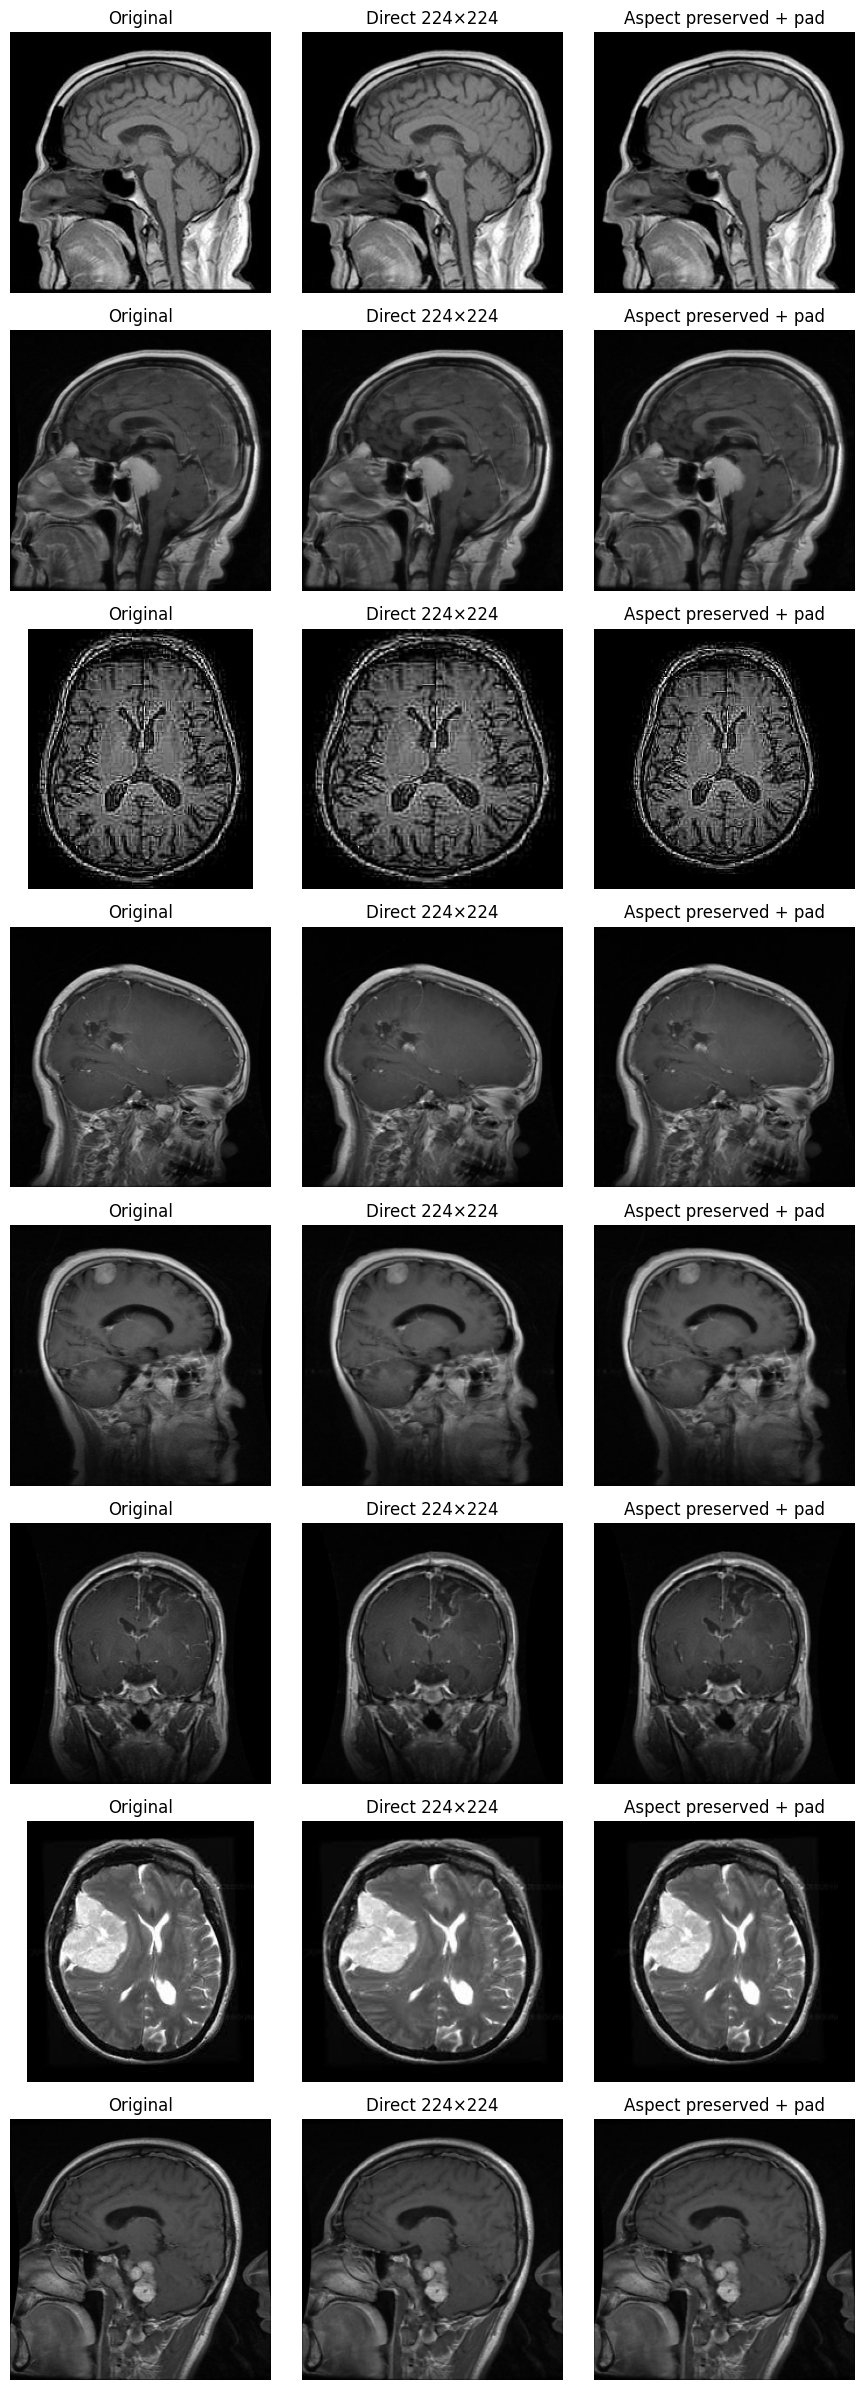

In [12]:
print("Dimension summary:")
display(stats_df[["width","height","aspect_ratio"]].describe().round(2))
print("Images with non-square aspect ratio:", int((np.abs(stats_df.aspect_ratio-1) > 0.02).sum()))
print("Unreadable images:", int(stats_df.get("read_error", pd.Series(dtype=object)).notna().sum()))

# Visual comparison: original, direct square resize, aspect-preserving resize + padding.
def resize_with_pad(img, target=(224,224)):
    img = img.convert("RGB")
    img.thumbnail((target[1], target[0]))
    canvas = Image.new("RGB", (target[1], target[0]), (0,0,0))
    x = (target[1]-img.width)//2
    y = (target[0]-img.height)//2
    canvas.paste(img, (x,y))
    return canvas

sample_paths = manifest.sample(min(8,len(manifest)), random_state=SEED).path.tolist()
fig, axes = plt.subplots(len(sample_paths), 3, figsize=(9, 3*len(sample_paths)))
if len(sample_paths)==1: axes=np.expand_dims(axes,0)
for i,p in enumerate(sample_paths):
    im=Image.open(p).convert("RGB")
    axes[i,0].imshow(im); axes[i,0].set_title("Original")
    axes[i,1].imshow(im.resize((224,224))); axes[i,1].set_title("Direct 224×224")
    axes[i,2].imshow(resize_with_pad(im)); axes[i,2].set_title("Aspect preserved + pad")
    for ax in axes[i]: ax.axis("off")
plt.tight_layout(); plt.show()

### Verify preprocessing compatibility

A ResNet50/VGG16 ImageNet-pretrained model normally expects its matching `preprocess_input` function. Do not apply `/255` and architecture-specific preprocessing together unless that exact combination was used during training. Inspect the saved model for embedded `Rescaling` or `Normalization` layers.

In [13]:
if model is not None:
    print("Input shape:", model.input_shape)
    print("Output shape:", model.output_shape)
    print("\\nPotential preprocessing layers:")
    for layer in model.layers:
        if any(term in layer.__class__.__name__.lower()+" "+layer.name.lower()
               for term in ["rescal","normal","preprocess"]):
            print(layer.name, layer.__class__.__name__, layer.get_config())

Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
\nPotential preprocessing layers:
batch_normalization_1 BatchNormalization {'name': 'batch_normalization_1', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'axis': -1, 'momentum': 0.99, 'epsilon': 0.001, 'center': True, 'scale': True, 'beta_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'gamma_initializer': {'module': 'keras.initializers', 'class_name': 'Ones', 'config': {}, 'registered_name': None}, 'moving_mean_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'moving_variance_initializer': {'module': 'keras.initializers', 'class_name': 'Ones', 'config': {}, 'registered_name': None}, 'beta_regularizer': None, 'gamma_regularizer': None, 'beta_constraint': None, 'gamma_constraint': None, 'synchronized': False}


## 8. Fine-tuning strategy audit

This section reports trainable/non-trainable parameter counts and BatchNormalization settings. It cannot infer the complete training history unless you saved the Keras History object or CSV logs. Use the training log CSV if available.

In [14]:
if model is not None:
    total_params = model.count_params()
    trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
    nontrainable_params = total_params - trainable_params
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,} ({trainable_params/total_params:.2%})")
    print(f"Non-trainable parameters: {nontrainable_params:,} ({nontrainable_params/total_params:.2%})")

    layer_rows=[]
    for i,layer in enumerate(model.layers):
        layer_rows.append({
            "index":i,"name":layer.name,"type":layer.__class__.__name__,
            "trainable":layer.trainable,
            "params":layer.count_params() if hasattr(layer,"count_params") else 0
        })
    layer_df=pd.DataFrame(layer_rows)
    display(layer_df.tail(40))
    bn_layers=[l for l in model.submodules if isinstance(l,tf.keras.layers.BatchNormalization)] if hasattr(model,"submodules") else []
    print("BatchNormalization layers:",len(bn_layers))
    print("Trainable BatchNormalization layers:",sum(l.trainable for l in bn_layers))
else:
    print("Load a model to inspect fine-tuning configuration.")

Total parameters: 24,121,476
Trainable parameters: 14,958,340 (62.01%)
Non-trainable parameters: 9,163,136 (37.99%)


,index,name,type,trainable,params
0,0,input_layer_5,InputLayer,True,0
1,1,data_augmentation,Sequential,True,0
2,2,resnet50,Functional,True,23587712
3,3,global_average_pooling2d_2,GlobalAveragePooling2D,True,0
4,4,batch_normalization_1,BatchNormalization,True,8192
5,5,dense_4,Dense,True,524544
6,6,dropout_2,Dropout,True,0
7,7,dense_5,Dense,True,1028


BatchNormalization layers: 0
Trainable BatchNormalization layers: 0


### Optional training-history analysis

Set `HISTORY_CSV` to a CSV exported from `history.history` or a Keras CSVLogger. A large train/validation gap can indicate overfitting; both low can indicate underfitting, poor preprocessing, or optimization issues.

In [15]:
HISTORY_CSV = None  # Example: PROJECT_DIR / "outputs" / "results" / "resnet50_history.csv"

if HISTORY_CSV and Path(HISTORY_CSV).exists():
    hist=pd.read_csv(HISTORY_CSV)
    display(hist.tail())
    for metric in ["accuracy","loss"]:
        val_metric="val_"+metric
        if metric in hist and val_metric in hist:
            plt.figure(figsize=(7,4))
            plt.plot(hist[metric],label="train")
            plt.plot(hist[val_metric],label="validation")
            plt.xlabel("Epoch"); plt.ylabel(metric); plt.title(f"Training history: {metric}")
            plt.legend(); plt.tight_layout(); plt.show()
else:
    print("No history CSV configured. Export history.history or use CSVLogger during training.")

No history CSV configured. Export history.history or use CSVLogger during training.


## 9. Consolidated diagnostic report

This creates a concise report of what was directly observed and what remains unassessed. It deliberately avoids converting warning signals into claims of confirmed root cause.

In [16]:
report = []

exact_cross_files = int(cross_split_exact.path.nunique()) if not cross_split_exact.empty else 0
conflicting_exact_files = int(conflicting_exact.path.nunique()) if not conflicting_exact.empty else 0
report.append(("1. Exact duplicate leakage",
               f"{exact_cross_files} files participate in exact cross-split duplicate groups.",
               "Review/remove duplicates from one split; verify patient-level separation."))
report.append(("2. Label inconsistency",
               f"{conflicting_exact_files} files participate in exact-duplicate groups with conflicting labels.",
               "Review against authoritative annotations; do not relabel from model predictions alone."))
report.append(("3. Background/acquisition bias",
               "Image statistics and metadata-only CV results are in image_statistics.csv and notebook output.",
               "Inspect class/split distribution shifts; use Grad-CAM and masking tests to verify shortcut reliance."))
report.append(("4. Feature separability",
               "Embedding plots and silhouette score are produced only when a compatible model is loaded.",
               "Inspect overlapping classes and validate with a patient-independent split."))
report.append(("5. Class imbalance",
               f"Train majority/minority count ratio: {imbalance_ratio:.2f}" if pd.notna(imbalance_ratio) else "Not available",
               "Use class weights or balanced sampling; collect more examples for underrepresented classes."))
report.append(("6. Resolution/preprocessing",
               f"{len(stats_df)} images inventoried; inspect dimension/aspect-ratio and resize comparison plots.",
               "Match inference preprocessing to training and assess aspect-preserving resize/crop alternatives."))
report.append(("7. Fine-tuning strategy",
               "Trainable parameter counts/layer configuration shown only when a model is loaded.",
               "Compare frozen-head training and controlled partial fine-tuning with identical data splits."))

report_df=pd.DataFrame(report,columns=["Potential issue","Evidence from this audit","Recommended follow-up"])
display(report_df)
report_df.to_csv(OUTPUT_DIR/"diagnostic_summary.csv",index=False)
print("Outputs saved to:", OUTPUT_DIR.resolve())

,Potential issue,Evidence from this audit,Recommended follow-up
0,1. Exact duplicate leakage,0 files participate in exact cross-split dupli...,Review/remove duplicates from one split; verif...
1,2. Label inconsistency,0 files participate in exact-duplicate groups ...,Review against authoritative annotations; do n...
2,3. Background/acquisition bias,Image statistics and metadata-only CV results ...,Inspect class/split distribution shifts; use G...
3,4. Feature separability,Embedding plots and silhouette score are produ...,Inspect overlapping classes and validate with ...
4,5. Class imbalance,Train majority/minority count ratio: 1.00,Use class weights or balanced sampling; collec...
5,6. Resolution/preprocessing,7200 images inventoried; inspect dimension/asp...,Match inference preprocessing to training and ...
6,7. Fine-tuning strategy,Trainable parameter counts/layer configuration...,Compare frozen-head training and controlled pa...


Outputs saved to: E:\SEM5\ERA\ERA_Project\Brain_Tumor\diagnostic_outputs


## 10. Interpretation checklist

Use this checklist when writing your project analysis:

- **Leakage:** Were exact/near duplicates found across train and test? Are patient IDs available to verify patient-level separation?
- **Labels:** Are there contradictory duplicate labels? Were suspicious cases checked against authoritative annotations?
- **Background/acquisition:** Do image statistics differ by class or split? Does Grad-CAM focus on the lesion rather than borders/text?
- **Feature separation:** Do embeddings form class-specific clusters? Which class pairs overlap?
- **Imbalance:** Which classes have the fewest training examples? Are per-class recall and macro-F1 more informative than accuracy?
- **Resolution:** Does direct resizing distort images? Does the model receive exactly the preprocessing used during training?
- **Fine-tuning:** How many parameters are trainable? Were BatchNormalization layers handled consistently? Do training curves suggest overfitting or underfitting?

### Important limitations

1. Folder labels are treated as the supplied labels, not verified diagnoses.
2. Model disagreement is only a review candidate.
3. Pixel statistics can reveal correlations, not prove shortcut learning.
4. t-SNE is a qualitative visualisation; cluster distances in t-SNE space should not be interpreted quantitatively.
5. Patient-level leakage cannot be ruled out without reliable patient identifiers.
6. This is a research/educational audit, not a clinical validation study.